In [4]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    BaggingClassifier,
    AdaBoostClassifier,
    RandomForestClassifier,
    VotingClassifier,
)
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42
print("All libraries imported successfully.")


All libraries imported successfully.



# Part 1: Data Cleaning, EDA & Reproducible Splitting


In [5]:

def load_ecommerce_dataset(filepath=None):
    candidates = [
        filepath,
        "E Commerce Dataset.xlsx",
        "E_Commerce_Dataset.xlsx",
        "ecommerce_churn.csv",
        "E Commerce Dataset.csv",
    ]
    for path in candidates:
        if path and os.path.exists(path):
            if path.endswith((".xlsx", ".xls")):
                xl = pd.ExcelFile(path)
                sheet = "E Comm" if "E Comm" in xl.sheet_names else xl.sheet_names[0]
                print(f"Loaded Excel file '{path}' (sheet: '{sheet}')")
                return pd.read_excel(path, sheet_name=sheet)
            else:
                print(f"Loaded CSV file '{path}'")
                return pd.read_csv(path)
    raise FileNotFoundError(
        "Dataset not found. Please place 'E Commerce Dataset.xlsx' or '.csv' "
        "in the working directory (or pass its path to load_ecommerce_dataset())."
    )

df = load_ecommerce_dataset()

print("Dataset Shape:", df.shape)
display(df.head())


Loaded Excel file 'E Commerce Dataset.xlsx' (sheet: 'E Comm')
Dataset Shape: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [6]:
print("=== Dataset Info ===")
df.info()

print("\n=== Missing Values per Column ===")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing (%)": missing_pct})
display(missing_df[missing_df["Missing Count"] > 0])

print("\n=== Descriptive Statistics (Numerical) ===")
display(df.describe().T)


=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 1

,Missing Count,Missing (%)
Tenure,264,4.69
WarehouseToHome,251,4.46
HourSpendOnApp,255,4.53
OrderAmountHikeFromlastYear,265,4.71
CouponUsed,256,4.55
OrderCount,258,4.58
DaySinceLastOrder,307,5.45



=== Descriptive Statistics (Numerical) ===


,count,mean,std,min,25%,50%,75%,max
CustomerID,5630.0,52815.500000,1625.385339,50001.0,51408.25,52815.50,54222.7500,55630.00
Churn,5630.0,0.168384,0.374240,0.0,0.00,0.00,0.0000,1.00
Tenure,5366.0,10.189899,8.557241,0.0,2.00,9.00,16.0000,61.00
CityTier,5630.0,1.654707,0.915389,1.0,1.00,1.00,3.0000,3.00
WarehouseToHome,5379.0,15.639896,8.531475,5.0,9.00,14.00,20.0000,127.00
HourSpendOnApp,5375.0,2.931535,0.721926,0.0,2.00,3.00,3.0000,5.00
NumberOfDeviceRegistered,5630.0,3.688988,1.023999,1.0,3.00,4.00,4.0000,6.00
SatisfactionScore,5630.0,3.066785,1.380194,1.0,2.00,3.00,4.0000,5.00
NumberOfAddress,5630.0,4.214032,2.583586,1.0,2.00,3.00,6.0000,22.00
Complain,5630.0,0.284902,0.451408,0.0,0.00,0.00,1.0000,1.00


In [7]:
if "CustomerID" in df.columns:
    df = df.drop(columns=["CustomerID"])
    print("Dropped 'CustomerID' column.")

dup_count = df.duplicated().sum()
print(f"Duplicate rows found: {dup_count}")
if dup_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Dropped {dup_count} duplicate rows. New shape: {df.shape}")
category_fixes = {
    "PreferredLoginDevice": {"Phone": "Mobile Phone"},
    "PreferredPaymentMode": {"CC": "Credit Card", "COD": "Cash on Delivery"},
    "PreferedOrderCat": {"Mobile": "Mobile Phone"},
}
for col, mapping in category_fixes.items():
    if col in df.columns:
        df[col] = df[col].replace(mapping)

print("Cleaned categorical label inconsistencies (if present).")
print("Current Dataset Shape:", df.shape)


Dropped 'CustomerID' column.
Duplicate rows found: 556
Dropped 556 duplicate rows. New shape: (5074, 19)
Cleaned categorical label inconsistencies (if present).
Current Dataset Shape: (5074, 19)


In [8]:
num_inspect_cols = df.select_dtypes(include=[np.number]).columns.drop("Churn", errors="ignore")

outlier_summary = []
for col in num_inspect_cols:
    series = df[col].dropna()
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    n_outliers = ((series < lower_bound) | (series > upper_bound)).sum()
    outlier_summary.append({
        "Feature": col,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": n_outliers,
        "Outlier (%)": round(n_outliers / len(series) * 100, 2),
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values("Outlier Count", ascending=False)
print("=== Outlier Inspection (1.5 x IQR Rule) ===")
display(outlier_df)


=== Outlier Inspection (1.5 x IQR Rule) ===


,Feature,Q1,Q3,Lower Bound,Upper Bound,Outlier Count,Outlier (%)
10,OrderCount,1.00,3.00,-2.00,6.0,673,13.93
9,CouponUsed,1.00,2.00,-0.50,3.5,610,12.54
12,CashbackAmount,145.92,197.95,67.86,276.0,382,7.53
4,NumberOfDeviceRegistered,3.00,4.00,1.50,5.5,363,7.15
11,DaySinceLastOrder,2.00,7.00,-5.50,14.5,57,1.19
8,OrderAmountHikeFromlastYear,13.00,18.00,5.50,25.5,29,0.60
3,HourSpendOnApp,2.00,3.00,0.50,4.5,6,0.12
0,Tenure,2.00,16.00,-19.00,37.0,4,0.08
6,NumberOfAddress,2.00,6.00,-4.00,12.0,4,0.08
2,WarehouseToHome,9.00,20.00,-7.50,36.5,2,0.04


### 1.2 Exploratory Data Analysis (EDA)

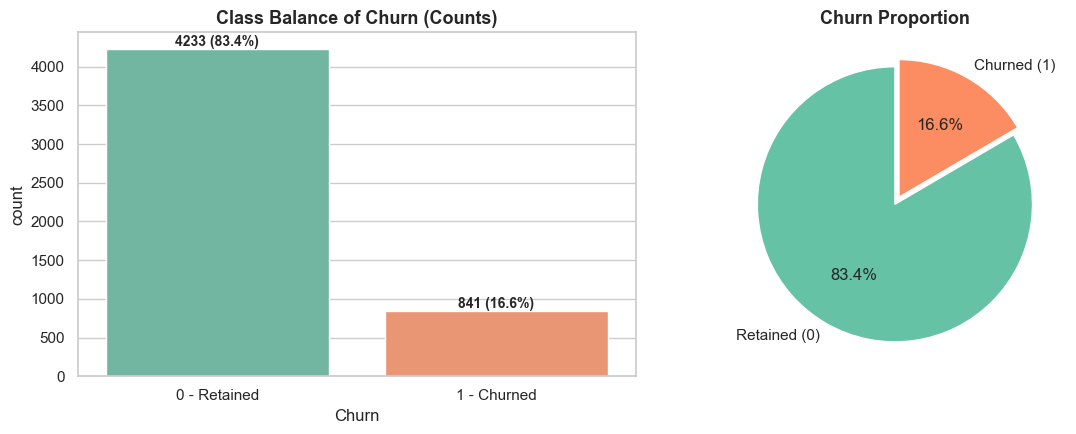

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

churn_counts = df["Churn"].value_counts().sort_index()
sns.countplot(x="Churn", data=df, ax=axes[0], palette="Set2")
axes[0].set_title("Class Balance of Churn (Counts)", fontsize=13, fontweight="bold")
axes[0].set_xticklabels(["0 - Retained", "1 - Churned"])
for p in axes[0].patches:
    axes[0].annotate(
        f"{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center", va="bottom", fontsize=10, fontweight="bold"
    )

axes[1].pie(
    churn_counts,
    labels=["Retained (0)", "Churned (1)"],
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2", 2),
    explode=(0, 0.06),
)
axes[1].set_title("Churn Proportion", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


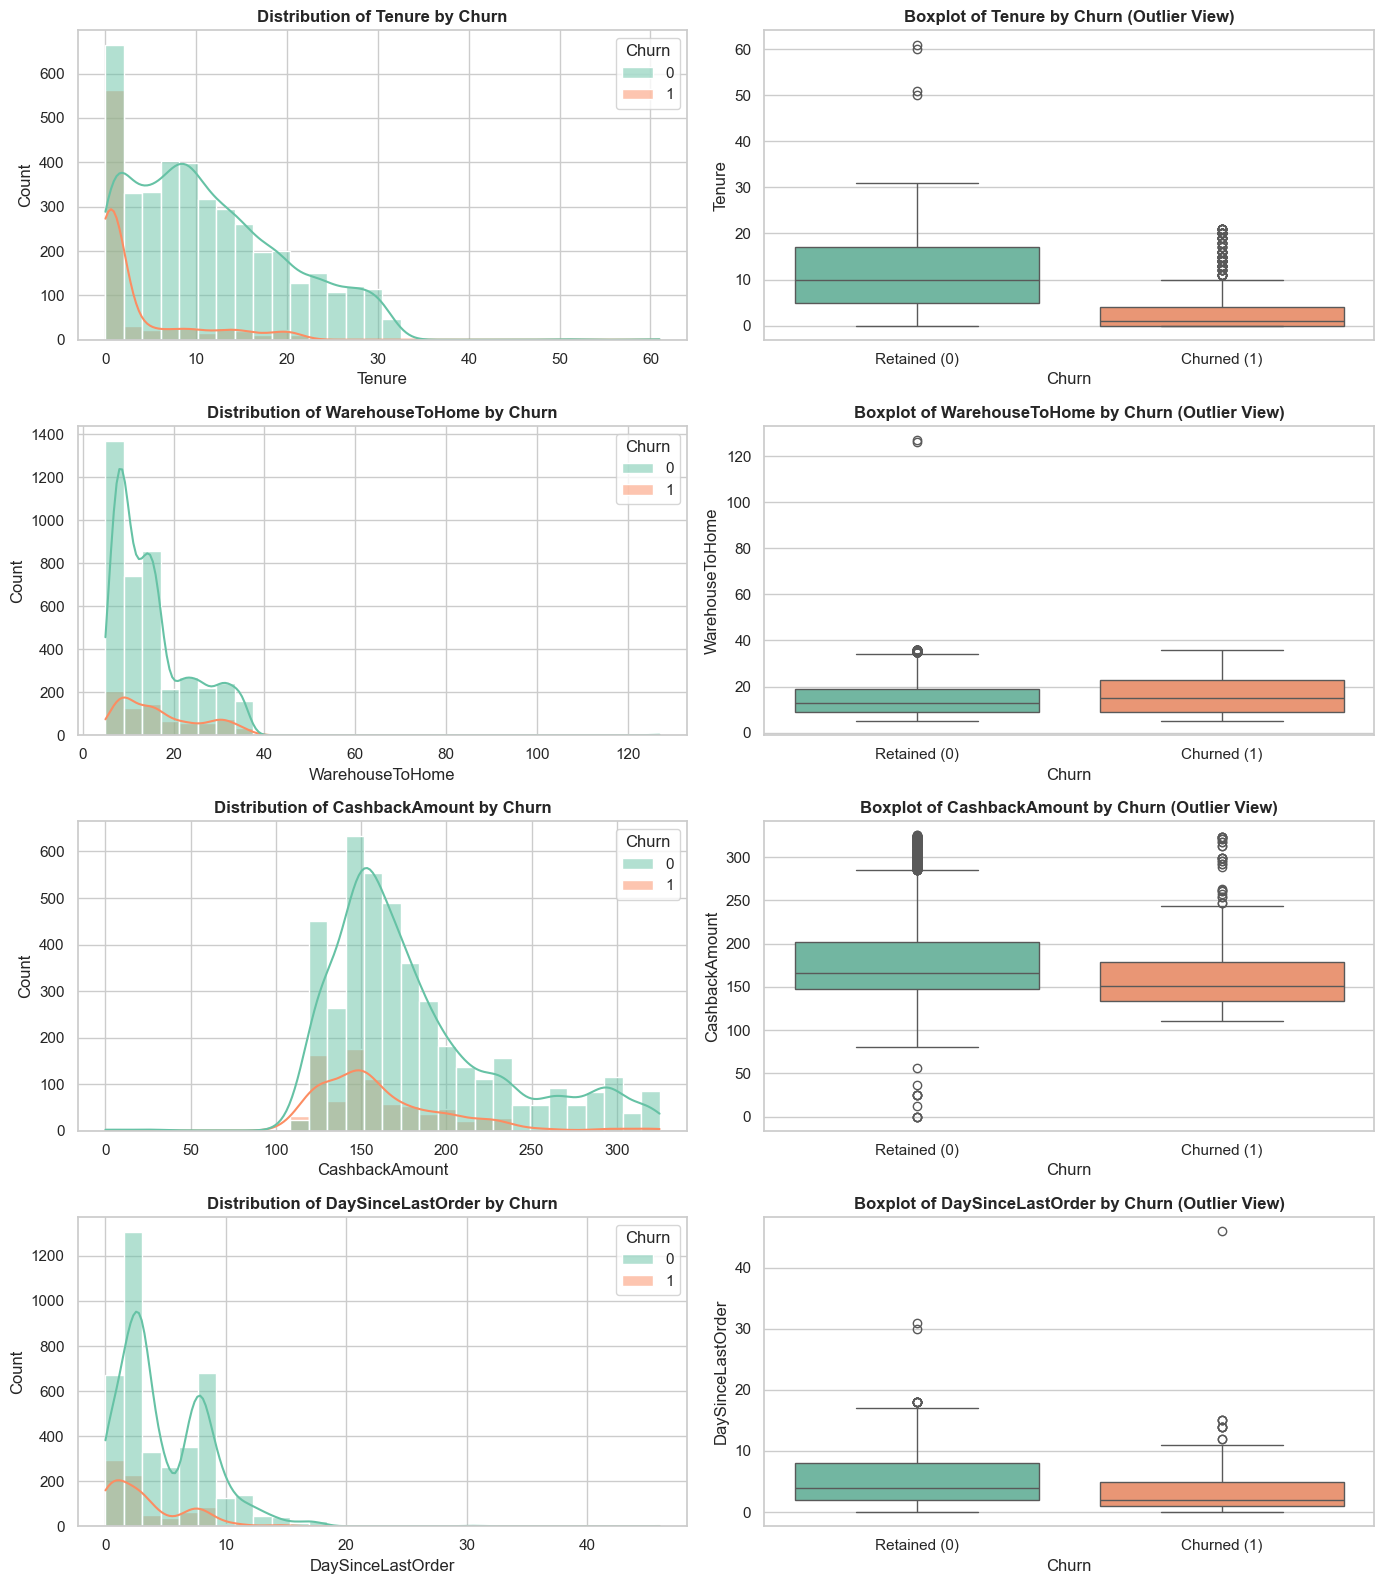

In [10]:
key_num_features = ["Tenure", "WarehouseToHome", "CashbackAmount", "DaySinceLastOrder"]
available_num = [c for c in key_num_features if c in df.columns]

fig, axes = plt.subplots(len(available_num), 2, figsize=(14, 4 * len(available_num)))
for i, col in enumerate(available_num):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, bins=30, ax=axes[i, 0], palette="Set2")
    axes[i, 0].set_title(f"Distribution of {col} by Churn", fontweight="bold")
    
    sns.boxplot(data=df, x="Churn", y=col, ax=axes[i, 1], palette="Set2")
    axes[i, 1].set_title(f"Boxplot of {col} by Churn (Outlier View)", fontweight="bold")
    axes[i, 1].set_xticklabels(["Retained (0)", "Churned (1)"])

plt.tight_layout()
plt.show()


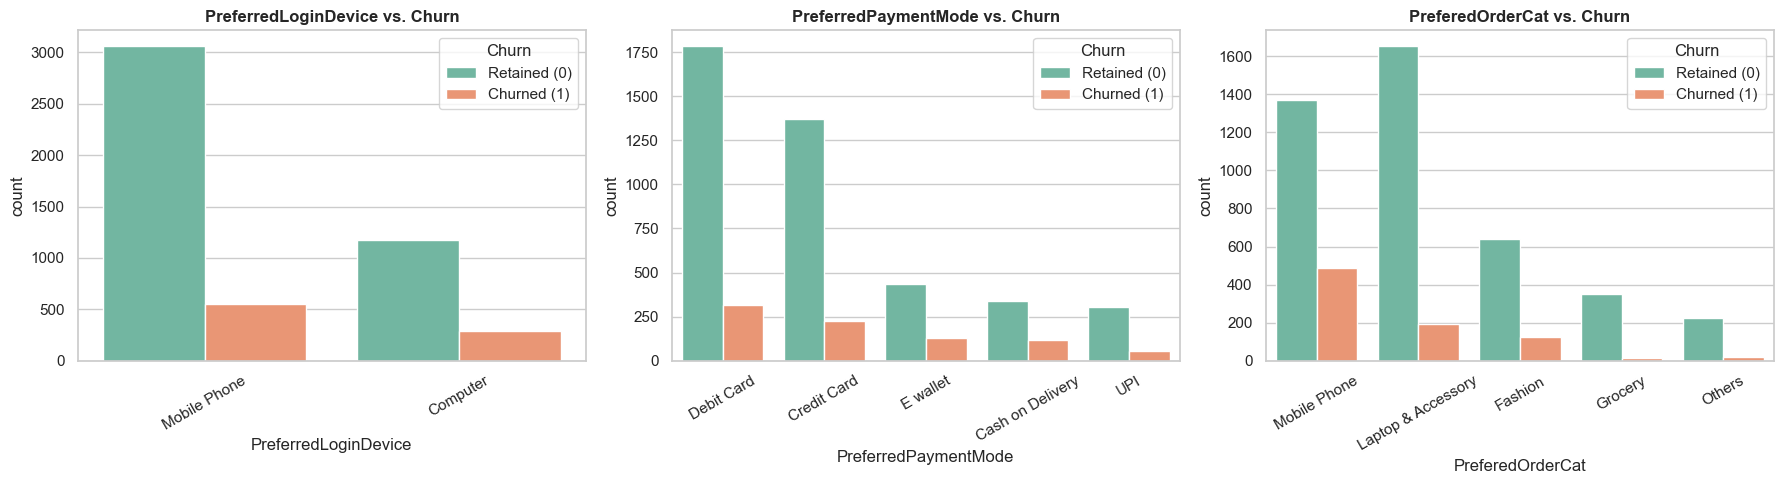

In [11]:
key_cat_features = ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]
available_cat = [c for c in key_cat_features if c in df.columns]

fig, axes = plt.subplots(1, len(available_cat), figsize=(18, 5))
if len(available_cat) == 1:
    axes = [axes]

for ax, col in zip(axes, available_cat):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, hue="Churn", order=order, ax=ax, palette="Set2")
    ax.set_title(f"{col} vs. Churn", fontsize=12, fontweight="bold")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Churn", labels=["Retained (0)", "Churned (1)"])

plt.tight_layout()
plt.show()


### 1.3 Train/Test Split



In [12]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print(f"Train Churn rate: {y_train.mean():.4f} | Test Churn rate: {y_test.mean():.4f}")


X_train shape: (4059, 18) | X_test shape: (1015, 18)
Train Churn rate: 0.1658 | Test Churn rate: 0.1655


#### Analytical Question 1: Why is setting random_state essential when splitting datasets in scikit-learn?

Setting random_state fixes the seed of the pseudo-random number generator used to shuffle the data before partitioning it into training and testing sets.



# Part 2: Preprocessing Pipelines

In [13]:
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

print(f"Numerical features ({len(num_cols)}): {num_cols}")
print(f"Categorical features ({len(cat_cols)}): {cat_cols}")
num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
])

# Build Categorical Pipeline: Most-Frequent Imputation -> One-Hot Encoding
cat_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])


Numerical features (13): ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
Categorical features (5): ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']


In [14]:
# === Attribute Inspection: SimpleImputer(strategy="median") ===
median_imputer = SimpleImputer(strategy="median")
median_imputer.fit(X_train[num_cols])

print("Learned medians stored in `median_imputer.statistics_`:")
for col, med in zip(num_cols, median_imputer.statistics_):
    print(f"  {col:30s}: {med:.4f}")

# Verify that .median_ does NOT exist as an attribute on SimpleImputer
print("\nHas attribute `.statistics_`?", hasattr(median_imputer, "statistics_"))
print("Has attribute `.median_`?    ", hasattr(median_imputer, "median_"))


Learned medians stored in `median_imputer.statistics_`:
  Tenure                        : 9.0000
  CityTier                      : 1.0000
  WarehouseToHome               : 13.0000
  HourSpendOnApp                : 3.0000
  NumberOfDeviceRegistered      : 4.0000
  SatisfactionScore             : 3.0000
  NumberOfAddress               : 3.0000
  Complain                      : 0.0000
  OrderAmountHikeFromlastYear   : 15.0000
  CouponUsed                    : 1.0000
  OrderCount                    : 2.0000
  DaySinceLastOrder             : 3.0000
  CashbackAmount                : 163.4900

Has attribute `.statistics_`? True
Has attribute `.median_`?     False


#### Analytical Question 2: Why is .statistics_ the standard attribute used across SimpleImputer strategies rather than .median_ ?

* SimpleImputer supports multiple imputation strategies: mean, median, and most_frequent.
* Regardless of which strategy is chosen, the fitted fill value for each feature is always stored in the single unified attribute **.statistics_**.
* If scikit-learn created strategy-specific attributes like .mean_, .median_, or .mode_, every downstream tool, pipeline inspector, or user script would have to write conditional logic just to retrieve the learned fill values. Using .statistics_ guarantees a uniform interface across all strategies.


In [15]:
cat_imputer_tmp = SimpleImputer(strategy="most_frequent")
X_train_cat_imputed = cat_imputer_tmp.fit_transform(X_train[cat_cols])

ohe = OneHotEncoder(handle_unknown="ignore")
X_train_cat_encoded = ohe.fit_transform(X_train_cat_imputed)

print("Output type of OneHotEncoder.fit_transform():", type(X_train_cat_encoded))
print("Encoded shape:", X_train_cat_encoded.shape)

dense_array = X_train_cat_encoded.toarray()
sparse_bytes = (
    X_train_cat_encoded.data.nbytes
    + X_train_cat_encoded.indices.nbytes
    + X_train_cat_encoded.indptr.nbytes
)
dense_bytes = dense_array.nbytes
density = X_train_cat_encoded.nnz / (X_train_cat_encoded.shape[0] * X_train_cat_encoded.shape[1])

print(f"Non-zero density: {density*100:.2f}% (meaning {(1-density)*100:.2f}% of entries are zeros)")
print(f"Sparse CSR memory: {sparse_bytes:,} bytes | Dense NumPy memory: {dense_bytes:,} bytes")


Output type of OneHotEncoder.fit_transform(): <class 'scipy.sparse._csr.csr_matrix'>
Encoded shape: (4059, 17)
Non-zero density: 29.41% (meaning 70.59% of entries are zeros)
Sparse CSR memory: 259,780 bytes | Dense NumPy memory: 552,024 bytes


#### Analytical Question 3: Why does scikit-learn's OneHotEncoder return a Sparse Matrix by default instead of a dense NumPy array?

One-Hot Encoding expands each categorical feature with k unique categories into k binary indicator columns, where **at most one entry per row is `1` and all remaining k-1 entries are `0`**.


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols),
    ],
    remainder="drop",
)

def build_pipeline(classifier):
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier),
    ])

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_train_pred = model.predict(X_tr)
    y_test_pred = model.predict(X_te)
    
    metrics = {
        "Model": name,
        "Train Accuracy": accuracy_score(y_tr, y_train_pred),
        "Test Accuracy": accuracy_score(y_te, y_test_pred),
        "Precision": precision_score(y_te, y_test_pred, zero_division=0),
        "Recall": recall_score(y_te, y_test_pred, zero_division=0),
        "F1-Score": f1_score(y_te, y_test_pred, zero_division=0),
    }
    return metrics, model

sample_pipe = build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
sample_pipe.fit(X_train, y_train)
print("Master Pipeline fitted successfully! Test Accuracy:", round(sample_pipe.score(X_test, y_test), 4))


Master Pipeline fitted successfully! Test Accuracy: 0.8847



# Part 3: Model Complexity, Bias–Variance Tradeoff & Regularization


In [ ]:
all_results = []

underfit_metrics, underfit_pipe = evaluate_model(
    "DecisionTree (max_depth=1, High Bias)",
    build_pipeline(DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE)),
    X_train, y_train, X_test, y_test
)
all_results.append(underfit_metrics)

overfit_metrics, overfit_pipe = evaluate_model(
    "DecisionTree (max_depth=None, Complex)",
    build_pipeline(DecisionTreeClassifier(max_depth=None, random_state=RANDOM_STATE)),
    X_train, y_train, X_test, y_test
)
all_results.append(overfit_metrics)


balanced_metrics, balanced_pipe = evaluate_model(
    "DecisionTree (max_depth=7, Balanced)",
    build_pipeline(DecisionTreeClassifier(max_depth=7, random_state=RANDOM_STATE)),
    X_train, y_train, X_test, y_test
)
all_results.append(balanced_metrics)

display(pd.DataFrame([underfit_metrics, balanced_metrics, overfit_metrics]).set_index("Model").round(4))


,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
Model,,,,,
"DecisionTree (max_depth=1, High Bias)",0.8436,0.8246,0.4779,0.6429,0.5482
"DecisionTree (max_depth=7, Balanced)",0.9293,0.8946,0.7293,0.5774,0.6445
"DecisionTree (max_depth=None, Complex)",1.0000,0.9537,0.8497,0.8750,0.8622


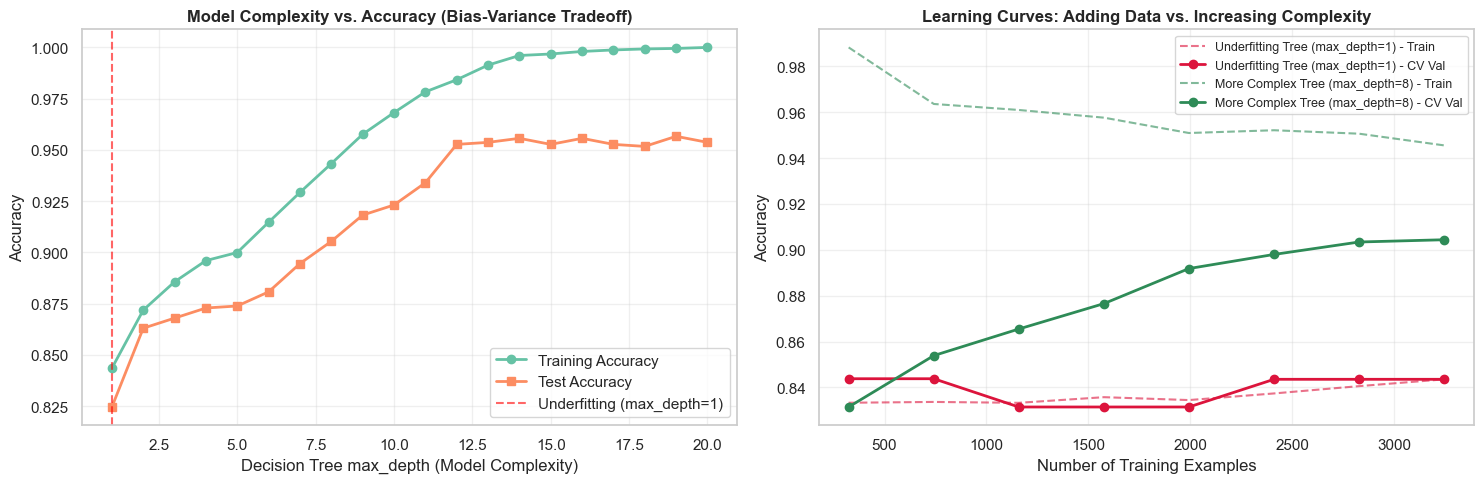

In [ ]:

depths = range(1, 21)
train_scores, test_scores = [], []

for d in depths:
    pipe = build_pipeline(DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))
    pipe.fit(X_train, y_train)
    train_scores.append(pipe.score(X_train, y_train))
    test_scores.append(pipe.score(X_test, y_test))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))


axes[0].plot(depths, train_scores, marker="o", label="Training Accuracy", linewidth=2)
axes[0].plot(depths, test_scores, marker="s", label="Test Accuracy", linewidth=2)
axes[0].axvline(x=1, color="red", linestyle="--", alpha=0.6, label="Underfitting (max_depth=1)")
axes[0].set_title("Model Complexity vs. Accuracy (Bias-Variance Tradeoff)", fontweight="bold")
axes[0].set_xlabel("Decision Tree max_depth (Model Complexity)")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

train_sizes = np.linspace(0.1, 1.0, 8)
for label, depth, color in [
    ("Underfitting Tree (max_depth=1)", 1, "crimson"),
    ("More Complex Tree (max_depth=8)", 8, "seagreen"),
]:
    pipe = build_pipeline(DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))
    sizes, tr_sc, val_sc = learning_curve(
        pipe, X_train, y_train, cv=5, train_sizes=train_sizes, scoring="accuracy", n_jobs=-1
    )
    axes[1].plot(sizes, tr_sc.mean(axis=1), "--", color=color, alpha=0.6, label=f"{label} - Train")
    axes[1].plot(sizes, val_sc.mean(axis=1), "-o", color=color, linewidth=2, label=f"{label} - CV Val")

axes[1].set_title("Learning Curves: Adding Data vs. Increasing Complexity", fontweight="bold")
axes[1].set_xlabel("Number of Training Examples")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


#### Analytical Question

**1. Describe what happens to bias and variance as the complexity of a machine learning model increases.**
* when the complexity of a machine learning model increases the bias decreases

* when the complexity of a machine learning model increases the variance increases

**2. If your model is underfitting the training data, explain why increasing model complexity resolves it, whereas simply adding more training examples does not.**

* because when you add more data to a already weak model this makes the bias more because this makes the model works more
* because adding a more complex model makes the model powerful enough for the data


### 3.2 Regularization & Shrinkage 


,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,Zero Coefs,L2 Norm ||w||
Model,,,,,,,
LogisticRegression (L2 - Ridge),0.8918,0.8847,0.7742,0.4286,0.5517,0 / 30,10.7044
LogisticRegression (L1 - Lasso),0.8953,0.8877,0.7455,0.4881,0.5899,3 / 30,14.4498
"LogisticRegression (Elastic Net, l1_ratio=0.5)",0.8938,0.8857,0.7653,0.4464,0.5639,4 / 30,12.0840


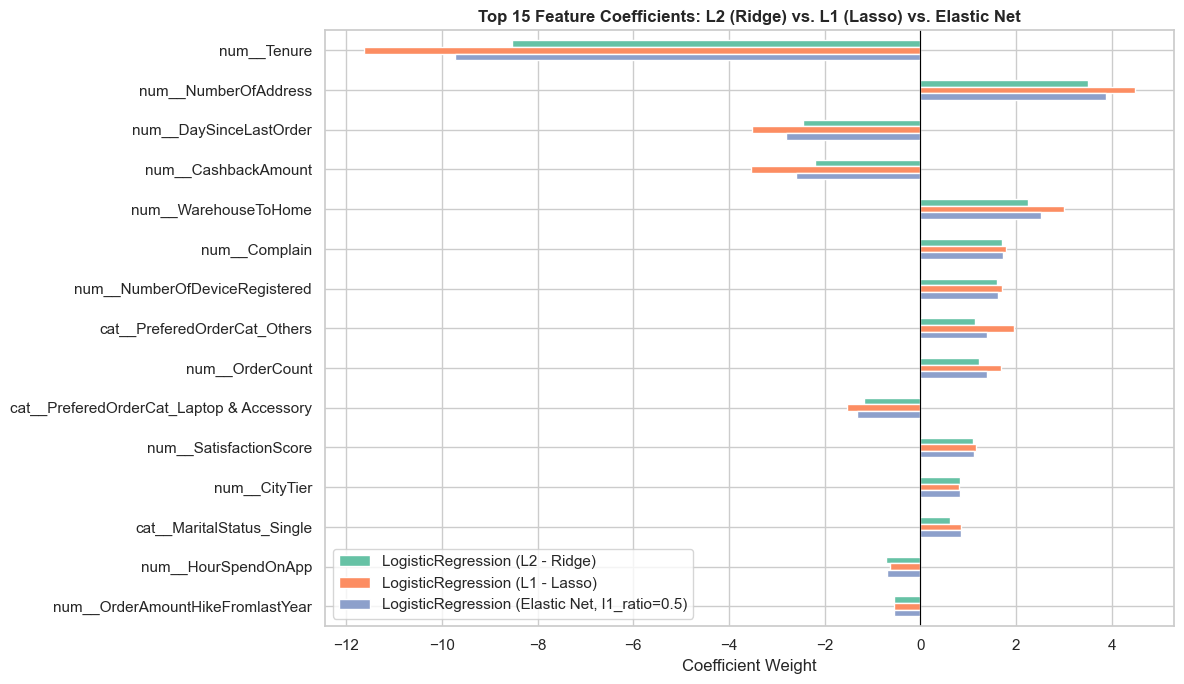

In [ ]:
reg_configs = [
    ("LogisticRegression (L2 - Ridge)", LogisticRegression(penalty="l2", C=1.0, solver="saga", max_iter=2000, random_state=RANDOM_STATE)),
    ("LogisticRegression (L1 - Lasso)", LogisticRegression(penalty="l1", C=1.0, solver="saga", max_iter=2000, random_state=RANDOM_STATE)),
    ("LogisticRegression (Elastic Net, l1_ratio=0.5)", LogisticRegression(penalty="elasticnet", l1_ratio=0.5, C=1.0, solver="saga", max_iter=2000, random_state=RANDOM_STATE)),
]

reg_results = []
coef_dict = {}

for name, clf in reg_configs:
    metrics, fitted_pipe = evaluate_model(name, build_pipeline(clf), X_train, y_train, X_test, y_test)
    coefs = fitted_pipe.named_steps["classifier"].coef_.ravel()
    zero_count = int(np.sum(np.isclose(coefs, 0.0, atol=1e-6)))
    metrics["Zero Coefs"] = f"{zero_count} / {len(coefs)}"
    metrics["L2 Norm ||w||"] = round(float(np.linalg.norm(coefs)), 4)
    
    reg_results.append(metrics)
    all_results.append({k: v for k, v in metrics.items() if k not in ["Zero Coefs", "L2 Norm ||w||"]})
    coef_dict[name] = coefs

reg_df = pd.DataFrame(reg_results).set_index("Model")
display(reg_df.round(4))
feature_names = fitted_pipe.named_steps["preprocessor"].get_feature_names_out()
coef_df = pd.DataFrame(coef_dict, index=feature_names)
top_features = coef_df.abs().mean(axis=1).sort_values(ascending=False).head(15).index

coef_df.loc[top_features].plot(kind="barh", figsize=(12, 7))
plt.title("Top 15 Feature Coefficients: L2 (Ridge) vs. L1 (Lasso) vs. Elastic Net", fontweight="bold")
plt.xlabel("Coefficient Weight")
plt.axvline(0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



# Part 4: Ensemble Learning

In [ ]:
bagging_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    n_estimators=200,
    max_samples=0.8,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
bagging_metrics, bagging_pipe = evaluate_model(
    "BaggingClassifier (bootstrap=True)",
    build_pipeline(bagging_clf),
    X_train, y_train, X_test, y_test,
)
all_results.append(bagging_metrics)

pasting_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    n_estimators=200,
    max_samples=0.8,
    bootstrap=False,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
pasting_metrics, pasting_pipe = evaluate_model(
    "BaggingClassifier (bootstrap=False / Pasting)",
    build_pipeline(pasting_clf),
    X_train, y_train, X_test, y_test,
)
all_results.append(pasting_metrics)

oob_acc = bagging_pipe.named_steps["classifier"].oob_score_
print(f"Bagging Out-of-Bag (OOB) Score : {oob_acc:.4f}")
print(f"Bagging Test Accuracy          : {bagging_metrics['Test Accuracy']:.4f}")
print(f"Difference (OOB - Test)        : {oob_acc - bagging_metrics['Test Accuracy']:+.4f}")

display(pd.DataFrame([bagging_metrics, pasting_metrics]).set_index("Model").round(4))


Bagging Out-of-Bag (OOB) Score : 0.9576
Bagging Test Accuracy          : 0.9665
Difference (OOB - Test)        : -0.0089


,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
Model,,,,,
BaggingClassifier (bootstrap=True),0.9998,0.9665,0.9467,0.8452,0.8931
BaggingClassifier (bootstrap=False / Pasting),1.0000,0.9685,0.9304,0.8750,0.9018


#### Analytical Questions (Part 4.1)

**1. What does setting n_jobs=-1 instruct scikit-learn to do?**
* Setting n_jobs=-1 makes the model uses all available CPU cores on the machine in parallel.

**2. Which ensemble technique is used when bootstrap=False is set in BaggingClassifier?**
* Bagging draws training subsets with replacement, Pasting draws training subsets without replacement.

**3. Compare oob_score_ against your test accuracy. What is the main advantage of using Out-of-Bag (OOB) evaluation?**
* Each training instance can be evaluated using only the subset of trees that did not see it during training, yielding `oob_score_`, which closely tracks the held-out test accuracy above.
* **Main Advantage:** OOB evaluation provides an unbiased, virtually free internal validation estimate during training without sacrificing training data to a separate validation split and without the computational cost of k fold cross-validation.


### 4.2 Boosting 


=== AdaBoost Evaluation Metrics ===
Accuracy  : 0.8818
Precision : 0.7222
Recall    : 0.4643
F1-Score  : 0.5652

Classification Report:
               precision    recall  f1-score   support

Retained (0)       0.90      0.96      0.93       847
 Churned (1)       0.72      0.46      0.57       168

    accuracy                           0.88      1015
   macro avg       0.81      0.71      0.75      1015
weighted avg       0.87      0.88      0.87      1015



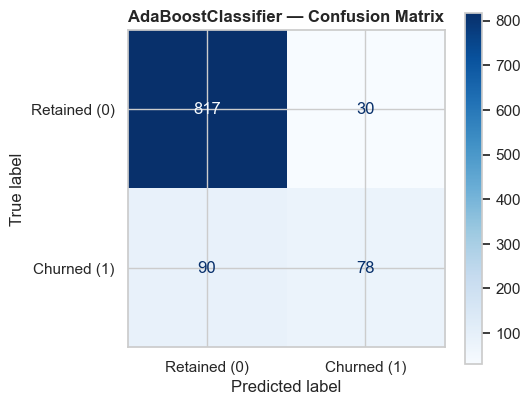

In [21]:
adaboost_clf = AdaBoostClassifier(
    n_estimators=150,
    learning_rate=0.5,
    random_state=RANDOM_STATE,
)
adaboost_metrics, adaboost_pipe = evaluate_model(
    "AdaBoostClassifier",
    build_pipeline(adaboost_clf),
    X_train, y_train, X_test, y_test,
)
all_results.append(adaboost_metrics)

y_pred_ada = adaboost_pipe.predict(X_test)
print("=== AdaBoost Evaluation Metrics ===")
print(f"Accuracy  : {adaboost_metrics['Test Accuracy']:.4f}")
print(f"Precision : {adaboost_metrics['Precision']:.4f}")
print(f"Recall    : {adaboost_metrics['Recall']:.4f}")
print(f"F1-Score  : {adaboost_metrics['F1-Score']:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_ada, target_names=["Retained (0)", "Churned (1)"]))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_ada, display_labels=["Retained (0)", "Churned (1)"], cmap="Blues", ax=ax
)
ax.set_title("AdaBoostClassifier — Confusion Matrix", fontweight="bold")
plt.tight_layout()
plt.show()


### 4.3 Voting Classifiers (Hard vs. Soft Voting)



In [ ]:
def make_base_estimators():
    return [
        ("lr", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
        ("rf", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
        ("svc", SVC(probability=True, random_state=RANDOM_STATE)),
    ]

indiv_results = []
for short_name, est in make_base_estimators():
    m, _ = evaluate_model(f"Individual: {short_name.upper()}", build_pipeline(est), X_train, y_train, X_test, y_test)
    indiv_results.append(m)

hard_voting_clf = VotingClassifier(estimators=make_base_estimators(), voting="hard", n_jobs=-1)
hard_metrics, hard_pipe = evaluate_model(
    "VotingClassifier (Hard Voting)",
    build_pipeline(hard_voting_clf),
    X_train, y_train, X_test, y_test,
)
all_results.append(hard_metrics)

soft_voting_clf = VotingClassifier(estimators=make_base_estimators(), voting="soft", n_jobs=-1)
soft_metrics, soft_pipe = evaluate_model(
    "VotingClassifier (Soft Voting)",
    build_pipeline(soft_voting_clf),
    X_train, y_train, X_test, y_test,
)
all_results.append(soft_metrics)

voting_comparison_df = pd.DataFrame(indiv_results + [hard_metrics, soft_metrics]).set_index("Model")
display(voting_comparison_df.round(4))


,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
Model,,,,,
Individual: LR,0.8921,0.8847,0.7742,0.4286,0.5517
Individual: RF,1.0000,0.9685,0.9595,0.8452,0.8987
Individual: SVC,0.9012,0.8857,0.8333,0.3869,0.5285
VotingClassifier (Hard Voting),0.9187,0.9015,0.8953,0.4583,0.6063
VotingClassifier (Soft Voting),0.9441,0.9074,0.8627,0.5238,0.6519


,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
Model,,,,,
BaggingClassifier (bootstrap=False / Pasting),1.0000,0.9685,0.9304,0.8750,0.9018
BaggingClassifier (bootstrap=True),0.9998,0.9665,0.9467,0.8452,0.8931
"DecisionTree (max_depth=None, Complex)",1.0000,0.9537,0.8497,0.8750,0.8622
VotingClassifier (Soft Voting),0.9441,0.9074,0.8627,0.5238,0.6519
"DecisionTree (max_depth=7, Balanced)",0.9293,0.8946,0.7293,0.5774,0.6445
VotingClassifier (Hard Voting),0.9187,0.9015,0.8953,0.4583,0.6063
LogisticRegression (L1 - Lasso),0.8953,0.8877,0.7455,0.4881,0.5899
AdaBoostClassifier,0.8960,0.8818,0.7222,0.4643,0.5652
"LogisticRegression (Elastic Net, l1_ratio=0.5)",0.8938,0.8857,0.7653,0.4464,0.5639


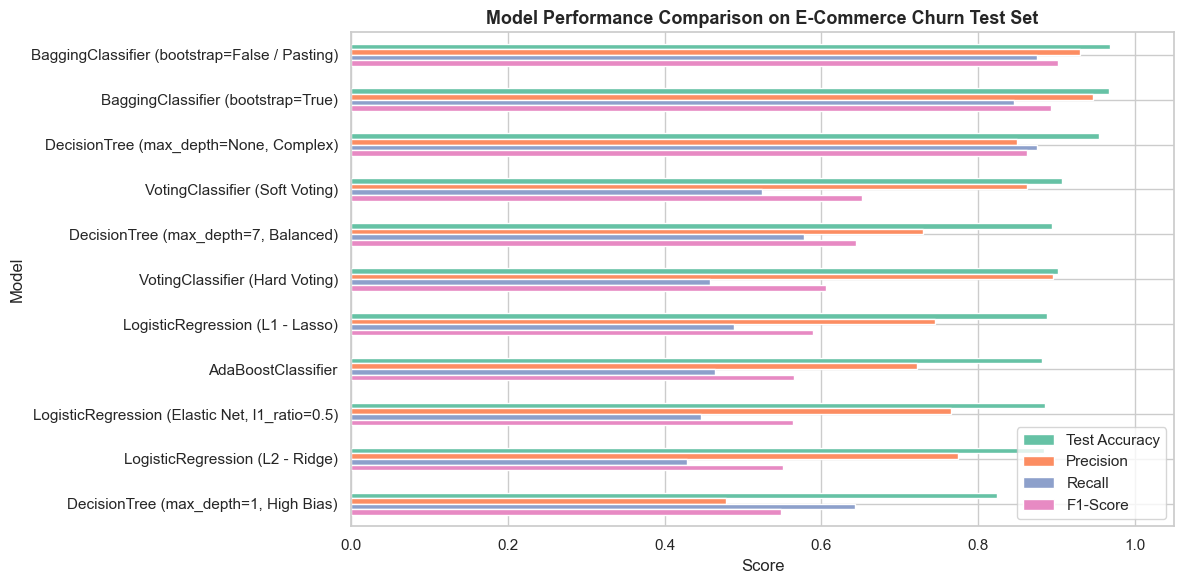

In [23]:
summary_df = pd.DataFrame(all_results).set_index("Model").sort_values("F1-Score", ascending=False)
display(summary_df.round(4))

fig, ax = plt.subplots(figsize=(12, 6))
summary_df[["Test Accuracy", "Precision", "Recall", "F1-Score"]].plot(kind="barh", ax=ax)
ax.set_title("Model Performance Comparison on E-Commerce Churn Test Set", fontsize=13, fontweight="bold")
ax.set_xlabel("Score")
ax.set_xlim(0, 1.05)
ax.invert_yaxis()
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
